# 03 — Channels and noise

Loss, phase-insensitive amplification, isotropic excess noise, and Gaussian
phase diffusion -- and why the last one is deliberately *not* implemented
as a `GaussianChannel`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvcircuit as cv
from cvcircuit import channels

np.set_printoptions(precision=4, suppress=True)

## Loss

`loss(eta, nbar_env=0.0)`: transmittance `eta`, optional thermal
environment `nbar_env` (0 = vacuum, ordinary optical loss). It's a genuine
`GaussianChannel`, `X = sqrt(eta) I`, `Y = (1-eta)(hbar/2)(2 nbar_env+1) I`
-- see `docs/conventions.md`.

In [2]:
ch = channels.loss(0.7, hbar=2)
print("X =\n", ch.X)
print("Y =\n", ch.Y)

X =
 [[0.8367 0.    ]
 [0.     0.8367]]
Y =
 [[0.3 0. ]
 [0.  0.3]]


### Squeezing degradation vs. transmission

The signature effect: loss mixes the squeezed quadrature back towards
vacuum. In shot-noise units, `Var(x) = eta * exp(-2r) + (1 - eta)`.

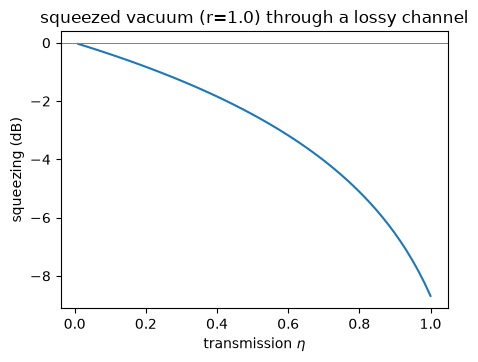

In [3]:
r = 1.0
etas = np.linspace(0.01, 1.0, 60)
squeezing_db = [cv.squeezed(r).loss(eta, mode=0).squeezing_db(0) for eta in etas]

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.plot(etas, squeezing_db)
ax.set_xlabel("transmission $\\eta$")
ax.set_ylabel("squeezing (dB)")
ax.set_title(f"squeezed vacuum (r={r}) through a lossy channel")
ax.axhline(0, color="gray", linewidth=0.7)

## Amplification and excess noise

In [4]:
vac = cv.vacuum(1)
amplified = vac.amplify(2.0, mode=0)
noisy = vac.add_noise(0.3, mode=0)
print("amplified cov:\n", amplified.cov)
print("noisy cov:\n", noisy.cov)

amplified cov:
 [[3. 0.]
 [0. 3.]]
noisy cov:
 [[1.3 0. ]
 [0.  1.3]]


## Composing channels

`GaussianChannel.compose()` (or the `@` operator) combines several
channels into one fixed `(X, Y)` map -- e.g. a lossy, noisy fibre link.

In [5]:
fibre = channels.loss(0.6, hbar=2).compose(channels.excess_noise(0.1, hbar=2))
direct = cv.squeezed(0.8).loss(0.6, mode=0).add_noise(0.1, mode=0)
via_composed = cv.squeezed(0.8).apply_channel(fibre, [0])
print("agrees:", np.allclose(direct.cov, via_composed.cov))

agrees: True


## Phase noise: why it isn't a `GaussianChannel`

A `GaussianChannel` is a *fixed* linear map `(X, Y)` -- the same
transformation regardless of the input state. But averaging a Gaussian
state over a randomly diffusing phase, φ ~ N(φ̄, σ²), does **not** produce
another Gaussian state whenever the input is displaced or anisotropically
squeezed: the true output is a genuinely non-Gaussian mixture of rotated
Gaussians. `phase_noise()` instead tracks the *exact* first and second
moments of that mixture -- the same "Gaussian-equivalent phase noise"
approximation used throughout the CV-QKD literature, made explicit.

In [6]:
# a squeezed, displaced state
s = cv.squeezed(0.8).displace(1.5 + 0.3j)

# compare phase_noise(sigma, mean_phase) against an ordinary fixed
# rotation by mean_phase (sigma=0 -> phase_noise reduces to a pure rotation)
mean_phase = 0.4
rotated = s.rotate(mean_phase, mode=0)
zero_noise = s.phase_noise(0.0, mode=0, mean_phase=mean_phase)
print("sigma=0 matches a plain rotation:", np.allclose(rotated.cov, zero_noise.cov, atol=1e-10))

for sigma in [0.0, 0.1, 0.3, 0.6, 1.5]:
    noisy = s.phase_noise(sigma, mode=0, mean_phase=mean_phase)
    print(f"sigma={sigma:4.1f}: mean={noisy.mean}  purity={noisy.purity():.4f}  "
          f"(tracked Gaussian-equivalent moments; true state is non-Gaussian for sigma>0)")

sigma=0 matches a plain rotation: True
sigma= 0.0: mean=[2.5295 1.7209]  purity=1.0000  (tracked Gaussian-equivalent moments; true state is non-Gaussian for sigma>0)
sigma= 0.1: mean=[2.5169 1.7123]  purity=0.8897  (tracked Gaussian-equivalent moments; true state is non-Gaussian for sigma>0)
sigma= 0.3: mean=[2.4182 1.6452]  purity=0.5375  (tracked Gaussian-equivalent moments; true state is non-Gaussian for sigma>0)
sigma= 0.6: mean=[2.1128 1.4374]  purity=0.2946  (tracked Gaussian-equivalent moments; true state is non-Gaussian for sigma>0)
sigma= 1.5: mean=[0.8212 0.5587]  purity=0.1482  (tracked Gaussian-equivalent moments; true state is non-Gaussian for sigma>0)


Two effects are visible above: the mean amplitude shrinks towards the
origin (a large phase spread eventually averages any coherent displacement
to zero -- the state becomes phase-randomized), and the tracked
"purity" of the *moment-matched Gaussian* need not stay at 1 even though
each individual rotated-Gaussian branch of the true mixture is pure --
because the true state is a **mixture**, not a single Gaussian, and only
its first two moments are what `phase_noise()` reports.

Text(0.5, 1.0, 'phase diffusion washes out the mean')

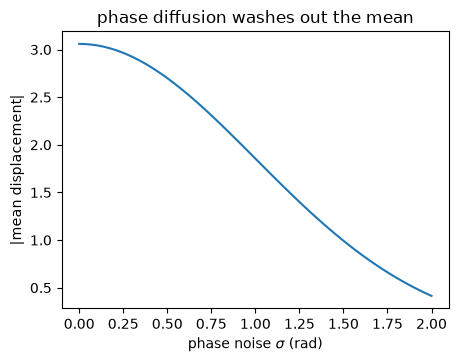

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.6))
sigmas = np.linspace(0, 2.0, 60)
mean_amplitudes = [abs(complex(*s.phase_noise(sig, mode=0, mean_phase=0.0).mean)) for sig in sigmas]
ax.plot(sigmas, mean_amplitudes)
ax.set_xlabel("phase noise $\\sigma$ (rad)")
ax.set_ylabel("|mean displacement|")
ax.set_title("phase diffusion washes out the mean")

## Monte Carlo cross-check

`phase_noise()`'s closed-form moments should match direct Monte Carlo
averaging over sampled rotation angles.

In [8]:
rng = np.random.default_rng(0)
sigma, mean_phase = 0.4, 0.5
closed_form = s.phase_noise(sigma, mode=0, mean_phase=mean_phase)

n_samples = 200_000
phis = rng.normal(mean_phase, sigma, size=n_samples)
samples = rng.multivariate_normal(s.mean, s.cov, size=n_samples)
c, sn = np.cos(phis), np.sin(phis)
rotated_samples = np.stack([c * samples[:, 0] - sn * samples[:, 1],
                              sn * samples[:, 0] + c * samples[:, 1]], axis=1)

print("mean:  closed form", closed_form.mean, " Monte Carlo", rotated_samples.mean(axis=0))
print("cov:   closed form\n", closed_form.cov, "\nMonte Carlo\n", np.cov(rotated_samples.T))

mean:  closed form [2.1648 1.8138]  Monte Carlo [2.1625 1.8191]
cov:   closed form
 [[ 2.2342 -2.0321]
 [-2.0321  4.3047]] 
Monte Carlo
 [[ 2.2347 -2.0396]
 [-2.0396  4.3164]]
